# ONIA 5.11 · Evaluarea și îmbunătățirea modelelor NLP

Notebook de lucru: seturi de date demonstrative, metrici, validare și analiza erorilor. Exemplele sunt independente. Necesită `scikit-learn`, `numpy`, `pandas`, `matplotlib`.

## Exemplul 1. Matrice de confuzie și metrici binare de la zero

In [1]:
reale = [1, 1, 0, 1, 0, 0, 1, 0, 0, 1]
prezise = [1, 0, 1, 1, 0, 0, 1, 0, 0, 0]
tp = fp = tn = fn = 0
for y, p in zip(reale, prezise):
    if y == 1 and p == 1:
        tp += 1
    elif y == 0 and p == 1:
        fp += 1
    elif y == 0 and p == 0:
        tn += 1
    else:
        fn += 1
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
print("TP, FP, TN, FN:", tp, fp, tn, fn)
print(f"Precision={precision:.3f}, Recall={recall:.3f}, F1={f1:.3f}")

TP, FP, TN, FN: 3 1 4 2
Precision=0.750, Recall=0.600, F1=0.667


## Exemplul 2. Macro-F1 de la zero, pentru trei clase

In [2]:
reale = ["sport", "sport", "sport", "tech", "tech", "educatie", "educatie"]
prezise = ["sport", "tech", "sport", "tech", "sport", "educatie", "tech"]
clase = ["sport", "tech", "educatie"]
f1_clase = []
for c in clase:
    tp = sum(y == c and p == c for y, p in zip(reale, prezise))
    fp = sum(y != c and p == c for y, p in zip(reale, prezise))
    fn = sum(y == c and p != c for y, p in zip(reale, prezise))
    scor = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    print(c, "TP=", tp, "FP=", fp, "FN=", fn, "F1=", round(scor, 3))
    f1_clase.append(scor)
print("Macro-F1 =", sum(f1_clase) / len(f1_clase))

sport TP= 2 FP= 1 FN= 1 F1= 0.667
tech TP= 1 FP= 2 FN= 1 F1= 0.4
educatie TP= 1 FP= 0 FN= 1 F1= 0.667
Macro-F1 = 0.5777777777777778


## Exemplul 3. Comparația macro, micro, weighted cu scikit-learn

In [3]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

reale = ["sport"] * 18 + ["tech"] * 2
prezise = ["sport"] * 20  # model trivial: nu prezice niciodată tech
print("Accuracy:", accuracy_score(reale, prezise))
for avg in ["macro", "micro", "weighted"]:
    print(avg, f1_score(reale, prezise, average=avg, zero_division=0))
print(classification_report(reale, prezise, zero_division=0))

Accuracy: 0.9
macro 0.47368421052631576
micro 0.9
weighted 0.8526315789473683
              precision    recall  f1-score   support

       sport       0.90      1.00      0.95        18
        tech       0.00      0.00      0.00         2

    accuracy                           0.90        20
   macro avg       0.45      0.50      0.47        20
weighted avg       0.81      0.90      0.85        20



## Exemplul 4. Matricea de confuzie multiclasă și ordinea etichetelor

[[1 0 1 0 0]
 [0 1 0 0 0]
 [1 0 1 0 0]
 [0 0 0 0 1]
 [0 0 0 0 1]]


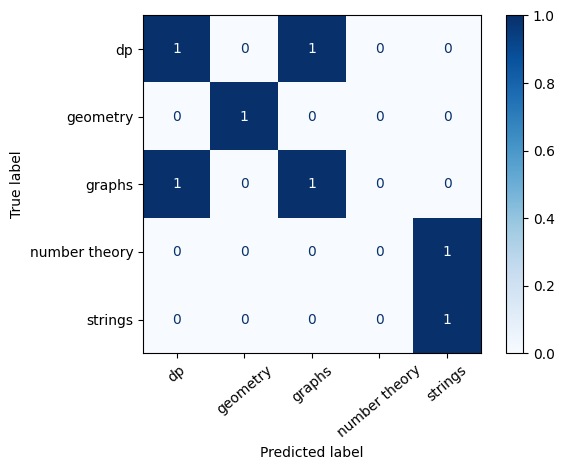

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

clase = ["dp", "geometry", "graphs", "number theory", "strings"]
y_true = ["dp", "graphs", "strings", "dp", "geometry", "graphs", "number theory"]
y_pred = ["dp", "dp", "strings", "graphs", "geometry", "graphs", "strings"]
mat = confusion_matrix(y_true, y_pred, labels=clase)
print(mat)
ConfusionMatrixDisplay(mat, display_labels=clase).plot(cmap="Blues", xticks_rotation=40)
plt.tight_layout()
plt.show()

## Exemplul 5. Validare stratificată: ce exemple intră în fiecare fold

In [5]:
from sklearn.model_selection import StratifiedKFold

y = ["sport"] * 6 + ["tech"] * 6 + ["educatie"] * 6
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
for nr, (train, val) in enumerate(cv.split(list(range(len(y))), y), 1):
    print(f"Fold {nr}: train={len(train)} validation={len(val)}")
    for clasa in sorted(set(y)):
        print(" ", clasa, "train=", sum(y[i] == clasa for i in train),
              "val=", sum(y[i] == clasa for i in val))

Fold 1: train=12 validation=6
  educatie train= 4 val= 2
  sport train= 4 val= 2
  tech train= 4 val= 2
Fold 2: train=12 validation=6
  educatie train= 4 val= 2
  sport train= 4 val= 2
  tech train= 4 val= 2
Fold 3: train=12 validation=6
  educatie train= 4 val= 2
  sport train= 4 val= 2
  tech train= 4 val= 2


## Exemplul 6. De ce TF-IDF se antrenează numai pe train

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

train = ["tenis sport meci", "python algoritm cod"]
validare = ["dijkstra graf ponderat"]
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train)
X_val = vectorizer.transform(validare)  # NU fit_transform!
print("Vocabular învățat:", vectorizer.get_feature_names_out().tolist())
print("Forme:", X_train.shape, X_val.shape)
print("Vectorul de validare are", X_val.nnz, "elemente nenule")

Vocabular învățat: ['algoritm', 'cod', 'meci', 'python', 'sport', 'tenis']
Forme: (2, 6) (1, 6)
Vectorul de validare are 0 elemente nenule


## Exemplul 7. Pipeline TF-IDF + LinearSVC cu predicții și raport

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

X_train = [
    "tenis meci sport", "fotbal stadion sport", "meci echipa fotbal",
    "finala tenis sport", "python program cod", "algoritm programare cod",
    "python date algoritm", "program python dezvoltare"
]
y_train = ["sport"] * 4 + ["tech"] * 4
X_val = ["meci stadion tenis", "cod programare python"]
y_val = ["sport", "tech"]
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", LinearSVC(C=1.0, random_state=0))
])
model.fit(X_train, y_train)
pred = model.predict(X_val)
print("Predicții:", pred.tolist())
print(classification_report(y_val, pred, labels=["sport", "tech"], zero_division=0))

Predicții: ['sport', 'tech']


              precision    recall  f1-score   support

       sport       1.00      1.00      1.00         1
        tech       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



## Exemplul 8. Cross-validation corect al întregului Pipeline

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

X = (["meci tenis sport", "fotbal stadion sport", "turneu sport echipa",
      "finala tenis", "sport meci final", "echipa fotbal meci"] +
     ["python cod algoritm", "programare date python", "algoritm cod executie",
      "python analiza date", "program cod functie", "biblioteca python cod"])
y = [0] * 6 + [1] * 6
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=7)
scoruri = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")
print("F1 pe folduri:", scoruri.round(3))
print("Media:", round(float(scoruri.mean()), 3))

F1 pe folduri: [1.    0.733 1.   ]
Media: 0.911


## Exemplul 9. GroupKFold împiedică trecerea aceleiași surse în ambele partiții

In [9]:
from sklearn.model_selection import GroupKFold

texte = ["stire A", "titlu A modificat", "stire B", "titlu B modificat",
         "stire C", "titlu C modificat", "stire D", "titlu D modificat"]
grupuri = ["A", "A", "B", "B", "C", "C", "D", "D"]
cv = GroupKFold(n_splits=4)
for nr, (train, val) in enumerate(cv.split(texte, groups=grupuri), 1):
    g_train = {grupuri[i] for i in train}
    g_val = {grupuri[i] for i in val}
    assert g_train.isdisjoint(g_val)
    print(nr, "grupuri train:", sorted(g_train), "validare:", sorted(g_val))

1 grupuri train: ['A', 'B', 'C'] validare: ['D']
2 grupuri train: ['A', 'B', 'D'] validare: ['C']
3 grupuri train: ['A', 'C', 'D'] validare: ['B']
4 grupuri train: ['B', 'C', 'D'] validare: ['A']


## Exemplul 10. GridSearchCV: n-grame și regularizarea C

In [10]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X = [
    "meci fotbal sport", "tenis turneu sport", "fotbal finala stadion",
    "sport echipa meci", "turneu tenis finala", "stadion echipa fotbal",
    "python cod algoritm", "programare python cod", "analiza date python",
    "functie algoritm cod", "biblioteca python date", "cod programare functie"
]
y = ["sport"] * 6 + ["tech"] * 6
pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
])
grid = GridSearchCV(
    pipe,
    param_grid={"tfidf__ngram_range": [(1, 1), (1, 2)],
                "clf__C": [0.1, 1.0, 10.0]},
    cv=StratifiedKFold(3, shuffle=True, random_state=0),
    scoring="f1_macro", refit=True
)
grid.fit(X, y)
print("Parametrii aleși:", grid.best_params_)
print("F1 mediu CV:", round(grid.best_score_, 3))

Parametrii aleși: {'clf__C': 0.1, 'tfidf__ngram_range': (1, 1)}
F1 mediu CV: 1.0


## Exemplul 11. Inspectarea lui cv_results_ și diferențele mici

In [11]:
import pandas as pd

date = pd.DataFrame({
    "configuratie": ["unigrame, C=0.1", "bigrame, C=1", "bigrame, C=10"],
    "mean_test_score": [0.802, 0.812, 0.807],
    "std_test_score": [0.025, 0.031, 0.029]
})
date = date.sort_values("mean_test_score", ascending=False)
print(date.to_string(index=False))
print("Diferența între primele două:", round(
    date.iloc[0]["mean_test_score"] - date.iloc[1]["mean_test_score"], 3))

   configuratie  mean_test_score  std_test_score
   bigrame, C=1            0.812           0.031
  bigrame, C=10            0.807           0.029
unigrame, C=0.1            0.802           0.025
Diferența între primele două: 0.005


## Exemplul 12. Analiza erorilor: extragem doar textele greșite

In [12]:
texte = ["meci pe stadion", "algoritm de graf", "programare dinamica",
         "numere prime", "distanta dintre puncte", "siruri de caractere"]
y_true = ["sport", "graphs", "dp", "number theory", "geometry", "strings"]
y_pred = ["sport", "dp", "dp", "dp", "geometry", "graphs"]
for i, (text, real, pred) in enumerate(zip(texte, y_true, y_pred)):
    if real != pred:
        print(f"#{i} real={real} pred={pred} | {text}")

#1 real=graphs pred=dp | algoritm de graf
#3 real=number theory pred=dp | numere prime
#5 real=strings pred=graphs | siruri de caractere


## Exemplul 13. Interpretarea coeficienților unui model liniar

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import numpy as np

texte = ["tenis sport meci", "fotbal stadion sport", "turneu sport tenis",
         "python cod algoritm", "programare python date", "cod algoritm date"]
y = [0, 0, 0, 1, 1, 1]
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000))
]).fit(texte, y)
termeni = model.named_steps["tfidf"].get_feature_names_out()
coef = model.named_steps["clf"].coef_[0]
pozitii = np.argsort(coef)
print("Sport:", [(termeni[i], round(float(coef[i]), 3)) for i in pozitii[:3]])
print("Tehnologie:", [(termeni[i], round(float(coef[i]), 3)) for i in pozitii[-3:]])

Sport: [('sport', -0.486), ('tenis', -0.385), ('turneu', -0.235)]
Tehnologie: [('python', 0.395), ('algoritm', 0.397), ('cod', 0.397)]


## Exemplul 14. Alegerea pragului pe o validare dedicată

In [14]:
from sklearn.metrics import f1_score

reale = [1, 1, 0, 1, 0, 0, 1, 0, 1, 0]
probabilitati = [0.94, 0.75, 0.72, 0.62, 0.55, 0.48, 0.44, 0.31, 0.26, 0.12]
rezultate = []
for prag in [0.3, 0.4, 0.5, 0.6, 0.7]:
    prezise = [int(p >= prag) for p in probabilitati]
    f1 = f1_score(reale, prezise, zero_division=0)
    rezultate.append((f1, prag))
    print(f"prag={prag:.1f}, F1={f1:.3f}")
print("Cel mai bun prag de validare:", max(rezultate))

prag=0.3, F1=0.615
prag=0.4, F1=0.667
prag=0.5, F1=0.600
prag=0.6, F1=0.667


prag=0.7, F1=0.500
Cel mai bun prag de validare: (0.6666666666666666, 0.6)


## Exemplul 15. Calibrarea empirică a probabilităților pe intervale

In [15]:
scoruri = [0.05, 0.12, 0.18, 0.27, 0.38, 0.44, 0.62, 0.75, 0.85, 0.94]
etichete = [0, 0, 0, 1, 0, 1, 1, 1, 0, 1]
for st, dr in [(0, 0.3), (0.3, 0.7), (0.7, 1.01)]:
    indicii = [i for i, p in enumerate(scoruri) if st <= p < dr]
    daca = len(indicii)
    if daca:
        medie_predictii = sum(scoruri[i] for i in indicii) / daca
        proportie_reala = sum(etichete[i] for i in indicii) / daca
        print(f"[{st:.1f}, {dr:.1f}): probabilitate medie {medie_predictii:.3f};"
              f" frecvență reală {proportie_reala:.3f}")

[0.0, 0.3): probabilitate medie 0.155; frecvență reală 0.250
[0.3, 0.7): probabilitate medie 0.480; frecvență reală 0.667
[0.7, 1.0): probabilitate medie 0.847; frecvență reală 0.667


## Exemplul 16. Curba de învățare pentru un Pipeline NLP

In [16]:
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import numpy as np

X = (["tenis sport meci", "sport finala tenis", "fotbal stadion meci",
      "echipa sport fotbal", "turneu sport tenis", "finala meci stadion",
      "fotbal meci echipa", "sport tenis finala", "meci sport echipa"] +
     ["python cod algoritm", "algoritm date python", "programare functie cod",
      "date programare python", "python analiza cod", "functie algoritm programare",
      "date cod biblioteca", "python functie programare", "algoritm python date"])
y = [0] * 9 + [1] * 9
model = Pipeline([("tfidf", TfidfVectorizer()),
                  ("clf", LogisticRegression(max_iter=1000))])
sizes, train, valid = learning_curve(
    model, X, y, train_sizes=[0.5, 0.75, 1.0],
    cv=StratifiedKFold(3, shuffle=True, random_state=42), scoring="f1_macro"
)
for n, tr, va in zip(sizes, train.mean(axis=1), valid.mean(axis=1)):
    print(f"{n:2d} exemple/fold | train={tr:.3f}, validation={va:.3f}")

 6 exemple/fold | train=nan, validation=nan
 9 exemple/fold | train=1.000, validation=0.693
12 exemple/fold | train=1.000, validation=1.000


/opt/pyvenv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:490: FitFailedWarning: 
3 fits failed out of a total of 9.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/pyvenv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/pyvenv/lib/python3.13/site-packages/sklearn/base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/opt/pyvenv/lib/python3.13/site-packages/sklearn/pipeline.py", line 621, in fit
    self._final_estimator.fit(Xt, y, **l

## Exemplul 17. Regresie pe texte și metrici corecte

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_train = ["text simplu", "cuvinte usoare", "exemplu elementar",
           "graf drumuri scurte", "programare dinamica complexa", "teorie avansata grafuri"]
y_train = [1.0, 1.2, 1.1, 3.0, 4.5, 4.0]
X_val = ["exemplu simplu", "graf complex"]
y_val = [1.2, 3.7]
model = Pipeline([("tfidf", TfidfVectorizer()), ("ridge", Ridge(alpha=1.0))])
model.fit(X_train, y_train)
pred = model.predict(X_val)
print("MAE:", mean_absolute_error(y_val, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, pred)))
print("R²:", r2_score(y_val, pred))

MAE: 0.8188532974413832
RMSE: 0.859297023403134
R²: 0.527429520365129


## Exemplul 18. Clasificare multilabel: mai multe valori pentru F1

In [18]:
from sklearn.metrics import f1_score, accuracy_score

y_true = [[1, 0, 1], [0, 1, 0], [1, 1, 0], [0, 0, 1]]
y_pred = [[1, 0, 0], [0, 1, 0], [1, 0, 1], [0, 0, 1]]
print("Micro-F1:", f1_score(y_true, y_pred, average="micro", zero_division=0))
print("Macro-F1:", f1_score(y_true, y_pred, average="macro", zero_division=0))
print("Samples-F1:", f1_score(y_true, y_pred, average="samples", zero_division=0))
print("Subset accuracy:", accuracy_score(y_true, y_pred))

Micro-F1: 0.7272727272727273
Macro-F1: 0.7222222222222222
Samples-F1: 0.7916666666666666
Subset accuracy: 0.5


## Exemplul 19. Jurnalizarea experimentelor fără dependențe externe

In [19]:
import csv

experimente = [
    {"model": "TF-IDF + LinearSVC", "ngrame": "1-1", "C": 1.0, "f1_macro_cv": 0.81},
    {"model": "TF-IDF + LinearSVC", "ngrame": "1-2", "C": 1.0, "f1_macro_cv": 0.82},
    {"model": "TF-IDF + LogisticRegression", "ngrame": "1-2", "C": 0.1, "f1_macro_cv": 0.80},
]
with open("experimente_demo.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(experimente[0]))
    writer.writeheader()
    writer.writerows(experimente)
print("Jurnal salvat:", len(experimente), "configurații")

Jurnal salvat: 3 configurații


## Exemplul 20. Validarea fișierului CSV pentru ONIA 266

In [20]:
import csv

id_uri = ["PROBLEM_0001", "PROBLEM_0002", "PROBLEM_0003"]
prezise = ["graphs", "strings", "number theory"]
permise = {"dp", "geometry", "graphs", "number theory", "strings"}
assert len(id_uri) == len(prezise)
assert len(set(id_uri)) == len(id_uri), "ID-uri duplicate"
assert all(label in permise for label in prezise), "Etichetă necunoscută"

with open("submisie_demo.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["id", "label"])
    writer.writerows(zip(id_uri, prezise))

with open("submisie_demo.csv", encoding="utf-8", newline="") as f:
    randuri = list(csv.DictReader(f))
assert [r["id"] for r in randuri] == id_uri
print("Format valid:", randuri)

Format valid: [{'id': 'PROBLEM_0001', 'label': 'graphs'}, {'id': 'PROBLEM_0002', 'label': 'strings'}, {'id': 'PROBLEM_0003', 'label': 'number theory'}]
